In [2]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet
from sklearn.model_selection import train_test_split

data = fetch_california_housing()
data



{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [6]:
X = pd.DataFrame(data = data.data, columns= data.feature_names)
y= data.target

X=X.head(350)
y=y[:350]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=123,shuffle=True)

linear_model = LinearRegression()
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=0.1)
elastic_net = ElasticNet(alpha=0.1)

linear_model.fit(X_train,y_train)
ridge.fit(X_train,y_train)
lasso.fit(X_train,y_train)
elastic_net.fit(X_train,y_train)


print("Linear regression coefficients")
print(linear_model.coef_)

print("ridge regression coefficients")
print(ridge.coef_)

print("lasso regression coefficients")
print(lasso.coef_)

print("elastic net regression coefficients")
print(elastic_net.coef_)

Linear regression coefficients
[ 3.11562118e-01 -5.73664081e-03 -1.41572292e-02 -1.00283573e+00
  8.98974036e-05 -5.68304571e-02  1.11950611e+01  1.81925913e+00]
ridge regression coefficients
[ 3.91956505e-01 -3.16654885e-03 -3.71028726e-02 -8.25969519e-01
  9.94790080e-05 -1.24957902e-01  1.33763185e+00 -1.15475391e+00]
lasso regression coefficients
[ 3.65639700e-01 -1.94216511e-03 -0.00000000e+00 -0.00000000e+00
  1.16068481e-04 -3.36210324e-02  0.00000000e+00 -0.00000000e+00]
elastic net regression coefficients
[ 3.70673937e-01 -2.15159482e-03 -0.00000000e+00 -0.00000000e+00
  1.12729579e-04 -8.22909642e-02  0.00000000e+00 -0.00000000e+00]


In [12]:
import matplotlib.pyplot as plt

def plot_coefficients(model,feature_names,title):

    coef_df = pd.DataFrame({
        "feature": feature_names,
        "coefficient": model.coef_})

    coef_df = coef_df.sort_values(by="coefficient")
    print(coef_df)

    plt.figure(figsize=(10,6))
    plt.barh(coef_df["feature"],coef_df["coefficient"])
    plt.title(title)
    plt.ylabel("feature")
    plt.xlabel("coefficient values")

    plt.tight_layout()
    plt.show()

      feature  coefficient
3   AveBedrms    -1.002836
5    AveOccup    -0.056830
2    AveRooms    -0.014157
1    HouseAge    -0.005737
4  Population     0.000090
0      MedInc     0.311562
7   Longitude     1.819259
6    Latitude    11.195061


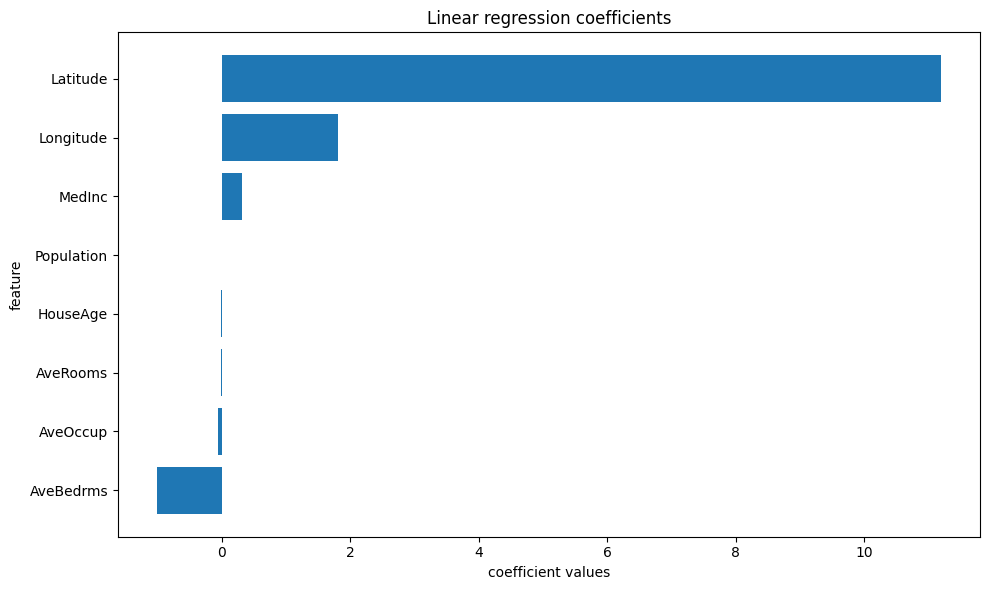

In [13]:
plot_coefficients(linear_model, X.columns,"Linear regression coefficients")

      feature  coefficient
7   Longitude    -1.154754
3   AveBedrms    -0.825970
5    AveOccup    -0.124958
2    AveRooms    -0.037103
1    HouseAge    -0.003167
4  Population     0.000099
0      MedInc     0.391957
6    Latitude     1.337632


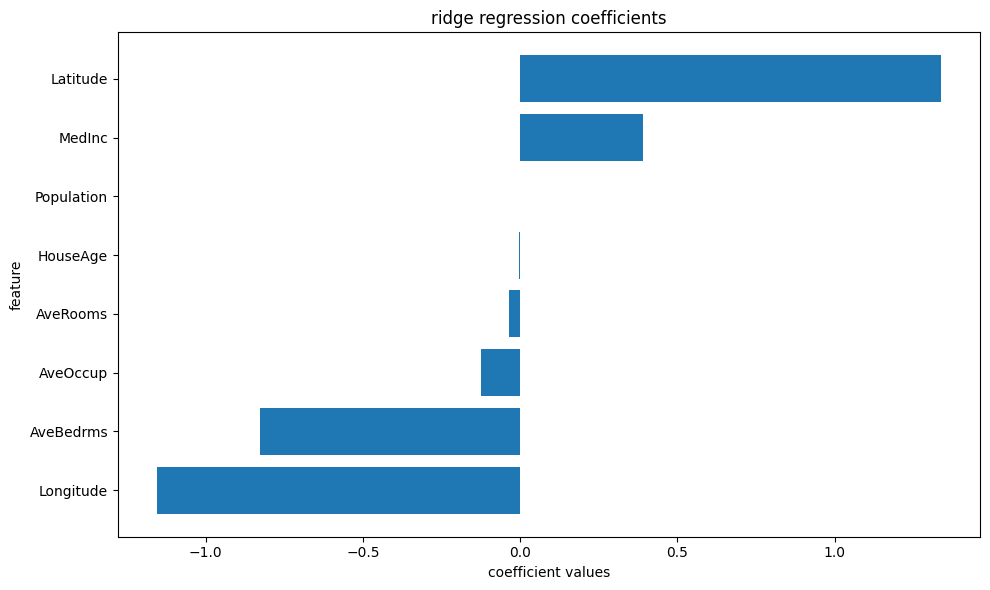

In [14]:
plot_coefficients(ridge, X.columns,"ridge regression coefficients")

      feature  coefficient
5    AveOccup    -0.033621
1    HouseAge    -0.001942
3   AveBedrms    -0.000000
2    AveRooms    -0.000000
7   Longitude    -0.000000
6    Latitude     0.000000
4  Population     0.000116
0      MedInc     0.365640


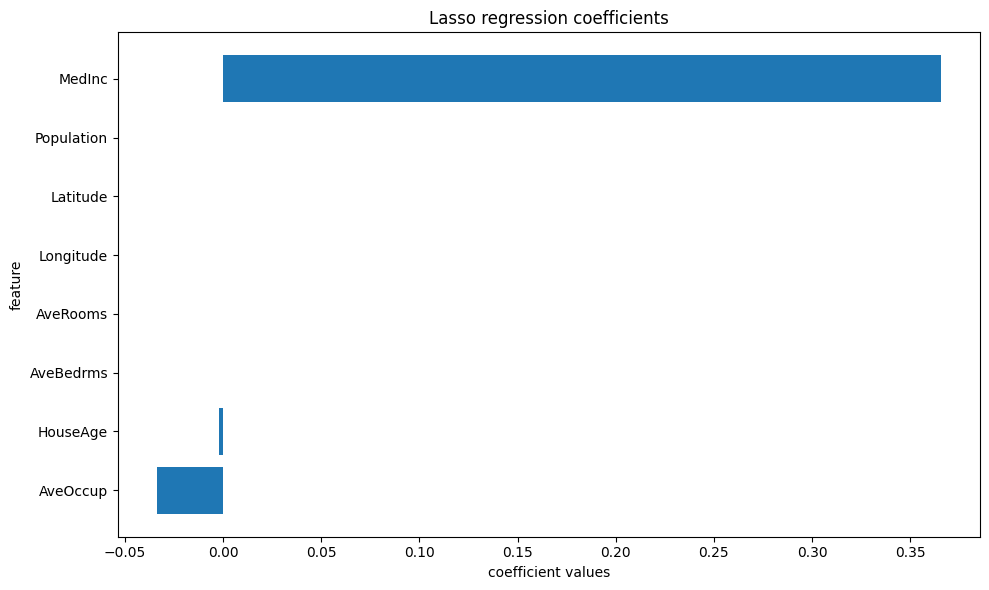

In [15]:
plot_coefficients(lasso, X.columns,"Lasso regression coefficients")

      feature  coefficient
5    AveOccup    -0.082291
1    HouseAge    -0.002152
3   AveBedrms    -0.000000
2    AveRooms    -0.000000
7   Longitude    -0.000000
6    Latitude     0.000000
4  Population     0.000113
0      MedInc     0.370674


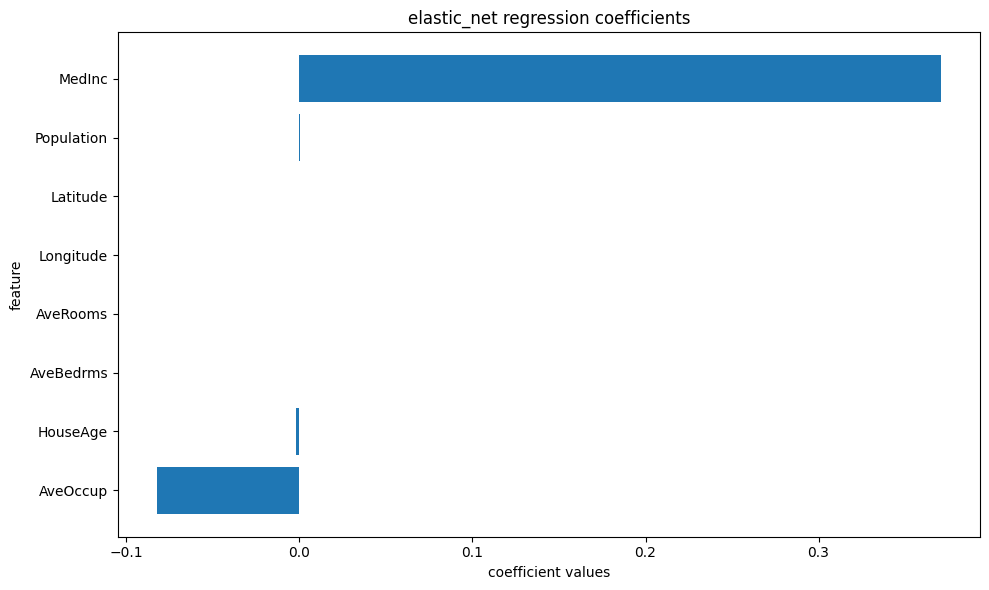

In [16]:
plot_coefficients(elastic_net, X.columns,"elastic_net regression coefficients")

In [18]:
from sklearn.metrics import mean_squared_error,r2_score

models = {
    "Linear":linear_model,
    "ridge":ridge,
    "lasso":lasso,
    "elastic net":elastic_net}

for name,model in models.items():
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test,y_pred)
    r2 = r2_score(y_test,y_pred)

    print(name)
    print("MSE:",mse)
    print("r2 score:",r2)
    print()
    

Linear
MSE: 0.18099579693537973
r2 score: 0.695162515603555

ridge
MSE: 0.20468083477301122
r2 score: 0.655271603911081

lasso
MSE: 0.23693083073344579
r2 score: 0.6009553832759449

elastic net
MSE: 0.220298733784796
r2 score: 0.6289675619005918

